# Bài thực hành 5: Cây quyết định và Rừng ngẫu nhiên

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu (số liệu mô phỏng dùng cho giảng dạy):
- `data/khach_vay.csv`: 600 hồ sơ khách vay, 5 cột `thu_nhap` (triệu đồng/tháng), `ty_le_no` (nợ chia thu nhập cả năm), `co_viec_on_dinh` (0/1), `so_nguoi_phu_thuoc` (0 tới 4), `tra_dung_han` (nhãn, 1 = đúng hạn).
- `data/gia_nha.csv`: dùng lại từ bài 1, 60 căn nhà, cột `dien_tich` và `gia` (tỷ đồng).

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap05/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab05/`, ví dụ `python baitap05/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải hai tệp lên
import os
CAN_CO = ["data/khach_vay.csv", "data/gia_nha.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca khach_vay.csv va gia_nha.csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/khach_vay.csv chua? True
Co data/gia_nha.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_1 = "#2a78d6"          # trả đúng hạn
MAU_0 = "#eb6834"          # trễ hạn
MAU_CHU = "#52514e"
NEN = ["#fbe1d6", "#d6e6f8"]   # nền vùng quyết định của lớp 0 và lớp 1
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})
HAI_COT = ["thu_nhap", "ty_le_no"]       # hai cột dùng để vẽ biên quyết định


def ve_bien(ax, mo_hinh, X, y, n=400):
    """Ve vung quyet dinh tren hai cot thu_nhap, ty_le_no va cac khach cua tap hoc."""
    gx, gy = np.meshgrid(np.linspace(4, 56, n), np.linspace(0, 1.3, n))
    luoi = pd.DataFrame({HAI_COT[0]: gx.ravel(), HAI_COT[1]: gy.ravel()})
    vung = mo_hinh.predict(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, vung, levels=[-0.5, 0.5, 1.5], colors=NEN)
    for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
        nhom = X[y == nhan]
        ax.scatter(nhom[HAI_COT[0]], nhom[HAI_COT[1]], c=mau, marker=mk, s=14,
                   edgecolor="white", linewidth=0.4)
    ax.set_xlabel("Thu nhập (triệu đồng)"); ax.grid(False)

## 1. Tự tính chỉ số Gini (`code/f1_gini.py`)

$$G = 1 - p_1^2 - p_0^2 \qquad\qquad G_{\text{chia}} = \frac{n_T}{n} G_T + \frac{n_P}{n} G_P$$

In [3]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay để tính tay, giống hệt bảng trên slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thử mọi ngưỡng nằm giữa hai mức thu nhập liền nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print("  nguong   Gini sau chia   Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f"  {nguong:6.1f}   {g:13.4f}   {g_goc - g:9.4f}")
print()

# Câu hỏi thứ hai: có việc làm ổn định không
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f"  Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# Để scikit-learn tự chọn câu hỏi đầu tiên rồi so với bảng ở trên
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
  nguong   Gini sau chia   Gini giam
     7.0          0.4000      0.0800
     8.5          0.4750      0.0050
    10.0          0.4190      0.0610
    12.0          0.3167      0.1633
    14.0          0.4000      0.0800
    16.5          0.4500      0.0300
    19.0          0.3429      0.1371
    22.5          0.4000      0.0800
    27.5          0.4444      0.0356

Cau hoi 'co viec on dinh ?'
  Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



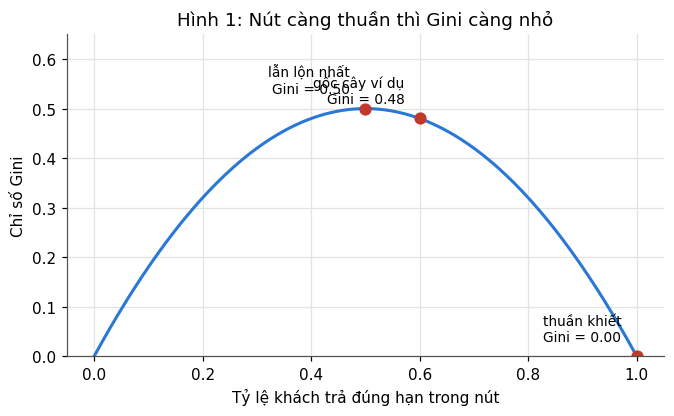

In [4]:
# Hình 1: chỉ số Gini theo tỷ lệ khách trả đúng hạn trong nút
p = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(p, 1 - p ** 2 - (1 - p) ** 2, color=MAU_1)
for x, chu in [(0.5, "lẫn lộn nhất\nGini = 0.50"), (0.6, "gốc cây ví dụ\nGini = 0.48"), (1.0, "thuần khiết\nGini = 0.00")]:
    g = 1 - x ** 2 - (1 - x) ** 2
    ax.plot(x, g, "o", color="#c0392b", ms=7)
    ax.annotate(chu, (x, g), textcoords="offset points", xytext=(-10, 10), ha="right", fontsize=9)
ax.set_xlabel("Tỷ lệ khách trả đúng hạn trong nút"); ax.set_ylabel("Chỉ số Gini"); ax.set_ylim(0, 0.65)
ax.set_title("Hình 1: Nút càng thuần thì Gini càng nhỏ"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số. Nút gốc có 6 khách đúng hạn và 4 khách trễ hạn, nên G = 1 − 0.6² − 0.4² = 0.48. Ngưỡng được đặt **giữa hai giá trị liền nhau**, vì mọi ngưỡng giữa 11 và 13 đều chia mười khách y như nhau, nên chỉ có 9 ngưỡng cần thử. Ngưỡng 12.0 làm Gini giảm nhiều nhất (0.1633): nhánh trái {6, 8, 9, 11} có 3 trễ và 1 đúng, nhánh phải có 1 trễ và 5 đúng. Ngưỡng 19.0 đứng thứ hai (0.1371). Câu hỏi về việc làm chỉ làm Gini giảm 0.0610, bằng đúng ngưỡng 10.0, vì hai câu hỏi đó chia mười khách giống hệt nhau (ba khách đầu không có việc ổn định).

`DecisionTreeClassifier(max_depth=1)` chọn đúng `thu_nhap <= 12.00` với `weights: [3, 1]` và `[1, 5]`. Số đứng trước là lớp 0 (trễ hạn). Cây chỉ lặp lại đúng phép tính này ở mọi nút, mỗi lần chọn câu hỏi tốt nhất ngay lúc đó mà không nhìn trước (cách chọn **tham lam**).

## 2. Cây đầu tiên trên dữ liệu khách vay (`code/f2_cay_nam_la.py`)

In [5]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("data/khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ được có 5 lá để còn đọc được bằng mắt
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc      : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Hai khách mới, đi theo cây để biết mỗi người rơi vào lá nào
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

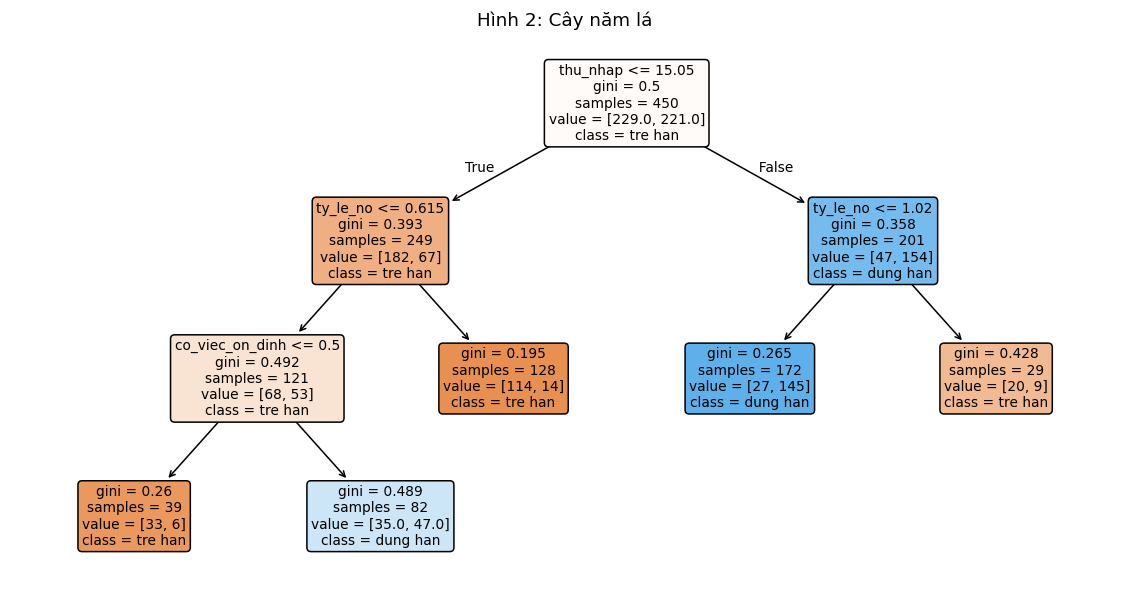

In [6]:
# Hình 2: cây năm lá vẽ bằng plot_tree (cam là trễ hạn, xanh là đúng hạn, càng đậm càng thuần)
fig, ax = plt.subplots(figsize=(13, 6.5))
plot_tree(cay, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Hình 2: Cây năm lá"); plt.show()

**Nhận xét.** Khớp tài liệu: 600 hồ sơ, tỷ lệ trả đúng hạn 0.49 (hai lớp gần cân bằng). Cây năm lá sâu 3 tầng, đạt 0.7978 trên tập học và 0.7467 trên tập kiểm tra.

Đọc cây từ trên xuống. Câu hỏi gốc là *thu nhập ≤ 15.05 triệu?* Nhánh thu nhập thấp hỏi tiếp tỷ lệ nợ với ngưỡng 0.615, nhánh thu nhập cao hỏi tỷ lệ nợ với ngưỡng 1.02. Chỉ riêng nhóm thu nhập thấp, nợ ít mới bị hỏi thêm câu thứ ba về việc làm ổn định. Luật đọc được như của một nhân viên ngân hàng, ví dụ: *thu nhập trên 15 triệu và nợ không quá một năm thu nhập thì cho vay* (lá 27 trễ / 145 đúng hạn).

Hai khách mới: khách 1 (20 triệu, nợ 0.4) rẽ phải rồi rơi vào lá [27, 145], nên `predict_proba` = 145/172 ≈ 0.84. Khách 2 (10 triệu, nợ 0.3, không có việc ổn định) đi qua ba câu hỏi tới lá [33, 6], xác suất đúng hạn 6/39 ≈ 0.15. Xác suất của cây chỉ là tỷ lệ trong lá, nên mọi khách cùng lá nhận cùng một xác suất.

Lá [35, 47] có Gini 0.489, gần mức lẫn lộn tối đa 0.5. Cây đoán "đúng hạn" ở lá này nhưng chỉ đúng khoảng 57%, và đó là chỗ một cây năm lá còn quá thô.

## 3. Cây học vẹt và cách chọn độ sâu (`code/f3_do_sau.py`)

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f"  do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f"  tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chọn độ sâu chỉ dựa trên tập học
print("Do sau   tap hoc   kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"  {d:2d}     {hoc:.4f}    {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Cay moc tu do
  do sau 13, so la 92
  tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc   kiem dinh cheo


   1     0.7467    0.7244
   2     0.7711    0.7378
   3     0.8000    0.7511
   4     0.8644    0.8089
   5     0.8978    0.8333
   6     0.9133    0.8156
   7     0.9400    0.8067
   8     0.9600    0.7733
   9     0.9800    0.7800
  10     0.9911    0.7822
  11     0.9933    0.7756


  12     0.9978    0.7778
  13     1.0000    0.7733


  14     1.0000    0.7733
  15     1.0000    0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


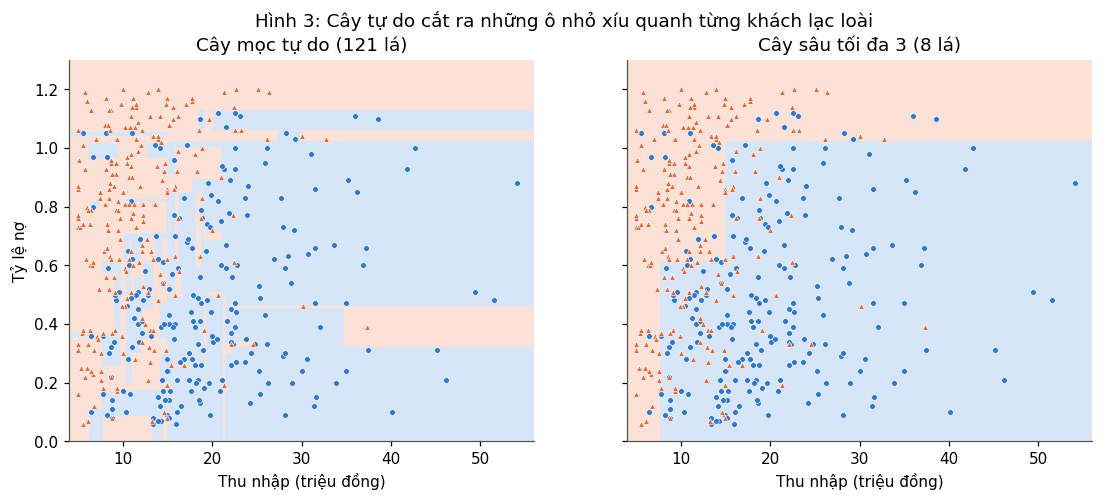

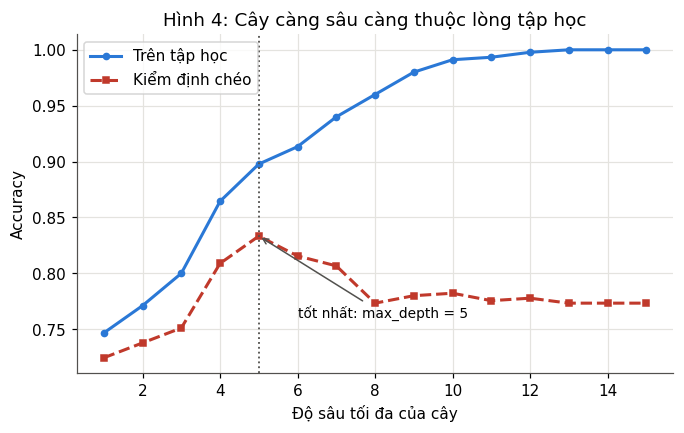

In [8]:
# Hình 3: biên quyết định của cây mọc tự do và cây sâu tối đa 3, học trên hai cột thu nhập và tỷ lệ nợ
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (ten, mh) in zip(axs, [("Cây mọc tự do", DecisionTreeClassifier(random_state=0)),
                               ("Cây sâu tối đa 3", DecisionTreeClassifier(max_depth=3, random_state=0))]):
    mh.fit(X_tr[HAI_COT], y_tr)
    ve_bien(ax, mh, X_tr, y_tr); ax.set_title(f"{ten} ({mh.get_n_leaves()} lá)")
axs[0].set_ylabel("Tỷ lệ nợ")
fig.suptitle("Hình 3: Cây tự do cắt ra những ô nhỏ xíu quanh từng khách lạc loài"); plt.show()

# Hình 4: accuracy trên tập học và điểm kiểm định chéo theo độ sâu
cac_d = list(diem)
hoc_d = [accuracy_score(y_tr, DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr).predict(X_tr)) for d in cac_d]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cac_d, hoc_d, "o-", color=MAU_1, ms=4, label="Trên tập học")
ax.plot(cac_d, [diem[d] for d in cac_d], "s--", color="#c0392b", ms=4, label="Kiểm định chéo")
ax.axvline(d_tot, ls=":", color=MAU_CHU, lw=1.2)
ax.annotate(f"tốt nhất: max_depth = {d_tot}", (d_tot, diem[d_tot]), xytext=(d_tot + 1, 0.76),
            arrowprops=dict(arrowstyle="->", color=MAU_CHU), fontsize=9)
ax.set_xlabel("Độ sâu tối đa của cây"); ax.set_ylabel("Accuracy")
ax.set_title("Hình 4: Cây càng sâu càng thuộc lòng tập học"); ax.legend(); plt.show()

**Nhận xét.** Khớp tài liệu. Cây mọc tự do sâu 13 tầng với 92 lá cho 450 khách, trung bình chưa tới 5 khách một lá. Nó đạt 1.0000 trên tập học nhưng chỉ 0.7667 trên tập kiểm tra: đó là **quá khớp**. Hình 3 (hai cây vẽ ở đây chỉ học trên hai cột thu nhập và tỷ lệ nợ để vẽ được lên mặt phẳng, nên số lá khác bảng) cho thấy cây tự do cắt ra những ô chữ nhật nhỏ để ôm từng khách lạc loài, ví dụ khách thu nhập cao, nợ ít mà vẫn trễ hạn. Cây sâu 3 chỉ giữ vài vùng lớn.

Bảng độ sâu và Hình 4 kể cùng một câu chuyện. Accuracy tập học tăng đều và chạm 1.0000 ở độ sâu 13. Điểm kiểm định chéo lên tới đỉnh **0.8333 ở độ sâu 5** rồi đi xuống, dừng quanh 0.77, đúng bằng cây tự do. Chọn độ sâu 5 (27 lá), chấm tập kiểm tra một lần được **0.8533**, cao hơn hẳn 0.7667 của cây tự do.

Độ sâu ngược chiều với k của KNN: ở KNN, k *nhỏ* là học vẹt; ở cây, độ sâu *lớn* mới là học vẹt. Cách chọn thì giống hệt: kiểm định chéo trên tập học, không nhìn tập kiểm tra.

## 4. Cây không cần chuẩn hoá (`code/f4_khong_chuan_hoa.py`)

In [9]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f"  du lieu goc        : {accuracy_score(y_te, du_goc):.4f}")
print(f"  da chuan hoa       : {accuracy_score(y_te, du_chuan):.4f}")
print(f"  thu nhap nghin dong: {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f"  da chuan hoa       : {(du_chuan != du_goc).sum()}")
print(f"  thu nhap nghin dong: {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f"  du lieu goc        : {goc.tree_.threshold[0]:.2f}")
print(f"  thu nhap nghin dong: {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
  du lieu goc        : 0.8533
  da chuan hoa       : 0.8533
  thu nhap nghin dong: 0.8533

So khach bi doan khac cay goc
  da chuan hoa       : 0
  thu nhap nghin dong: 0

Nguong cua cau hoi goc
  du lieu goc        : 15.05
  thu nhap nghin dong: 15050.00


**Nhận xét.** Khớp tài liệu. Ba cây sâu 5 trên dữ liệu gốc, dữ liệu đã chuẩn hoá và dữ liệu đổi thu nhập sang nghìn đồng đều đạt 0.8533, và **không khách kiểm tra nào bị đoán khác** (0 và 0). Chỉ có ngưỡng thay đổi: 15.05 thành 15050.00.

Lý do: mỗi câu hỏi của cây chỉ so **một cột với một ngưỡng**. Nhân cả cột với 1000 (hoặc trừ trung bình rồi chia độ lệch chuẩn) là phép biến đổi đồng biến, giữ nguyên thứ tự các giá trị. Khách nào ở bên trái ngưỡng vẫn ở bên trái, nên mọi cách chia và mức giảm Gini giống hệt. KNN thì cộng bình phương chênh lệch của mọi cột lại, nên đổi thang đo một cột là đổi cả khoảng cách (bài 4, bài tập 3: chỉ đổi đơn vị mà accuracy nhảy từ 0.5333 lên 0.8667). Chuẩn hoá không giúp gì cho cây nhưng cũng không làm hại, nên khi so nhiều mô hình trong một pipeline vẫn có thể giữ nó.

## 5. Rừng ngẫu nhiên (`code/f5_rung.py`)

In [10]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ 450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"  tap hoc      : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"  tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay   accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f"  {m:4d}   {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh          tap hoc   tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:14s} {a:.4f}    {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
  tap hoc      : 1.0000
  tap kiem tra : 0.9000

So cay   accuracy tap kiem tra
     1   0.7933
    10   0.8467


    50   0.8867
   200   0.9000


   400   0.9000

Mo hinh          tap hoc   tap kiem tra
  Cay moc tu do  1.0000    0.7667
  Cay sau 5      0.8978    0.8533
  Rung 200 cay   1.0000    0.9000


So cay: 1:0.7933 2:0.7933 3:0.8200 5:0.8467 10:0.8467 20:0.8600 50:0.8867 100:0.8800 200:0.9000 400:0.9000


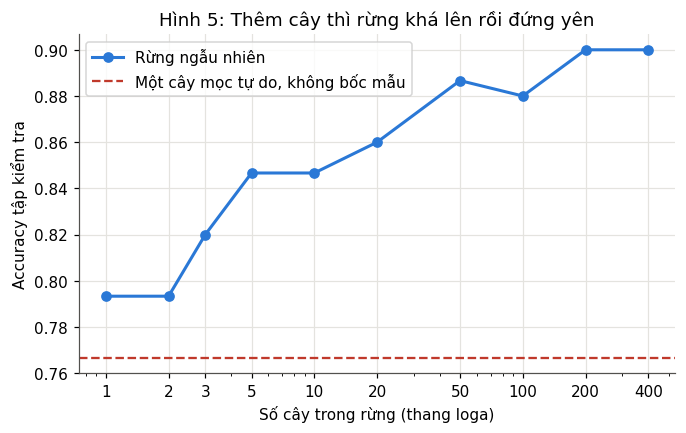

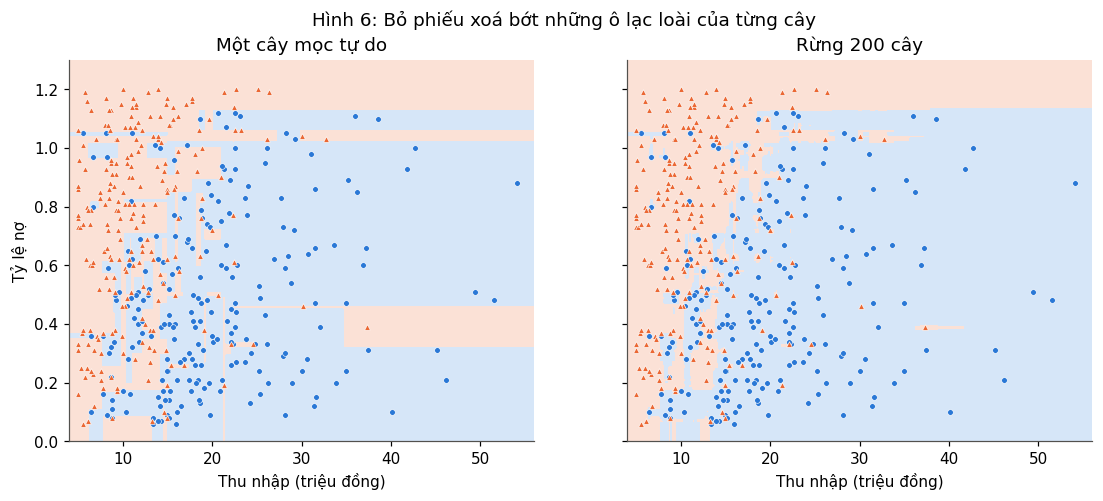

In [11]:
# Hình 5: accuracy trên tập kiểm tra theo số cây trong rừng
so_cay = [1, 2, 3, 5, 10, 20, 50, 100, 200, 400]
acc_rung = [accuracy_score(y_te, RandomForestClassifier(n_estimators=m, random_state=0).fit(X_tr, y_tr).predict(X_te)) for m in so_cay]
acc_tu_do = accuracy_score(y_te, DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr).predict(X_te))
print("So cay:", " ".join(f"{m}:{a:.4f}" for m, a in zip(so_cay, acc_rung)))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(so_cay, acc_rung, "o-", color=MAU_1, label="Rừng ngẫu nhiên")
ax.axhline(acc_tu_do, ls="--", color="#c0392b", lw=1.5, label="Một cây mọc tự do, không bốc mẫu")
ax.set_xscale("log"); ax.set_xticks(so_cay, [str(m) for m in so_cay])
ax.set_xlabel("Số cây trong rừng (thang loga)"); ax.set_ylabel("Accuracy tập kiểm tra")
ax.set_title("Hình 5: Thêm cây thì rừng khá lên rồi đứng yên"); ax.legend(); plt.show()

# Hình 6: biên quyết định của một cây mọc tự do và của rừng 200 cây, học trên hai cột
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (ten, mh) in zip(axs, [("Một cây mọc tự do", DecisionTreeClassifier(random_state=0)),
                               ("Rừng 200 cây", RandomForestClassifier(n_estimators=200, random_state=0))]):
    mh.fit(X_tr[HAI_COT], y_tr)
    ve_bien(ax, mh, X_tr, y_tr); ax.set_title(ten)
axs[0].set_ylabel("Tỷ lệ nợ")
fig.suptitle("Hình 6: Bỏ phiếu xoá bớt những ô lạc loài của từng cây"); plt.show()

**Nhận xét.** Rút 450 lần có hoàn lại từ 450 khách chỉ được 286 khách khác nhau (64%). Trung bình con số này tiến tới 1 − 1/e ≈ 63%, nên mỗi cây trong rừng chỉ thấy khoảng hai phần ba số khách, và mỗi cây hơi khác nhau.

Rừng 200 cây đạt 1.0000 trên tập học (mỗi cây đều mọc tự do) nhưng vẫn đạt **0.9000** trên tập kiểm tra, cao hơn cả cây sâu 5 đã được tỉa cẩn thận (0.8533) mà không cần dò tham số nào. Bảng tổng kết khớp tài liệu (1.0000 / 0.7667; 0.8978 / 0.8533; 1.0000 / 0.9000).

Bảng số cây khớp tài liệu ở 1, 10, 200, 400 cây (0.7933, 0.8467, 0.9000, 0.9000). Riêng 50 cây tôi được **0.8867**, còn tài liệu ghi 0.8733, lệch 2 trong 150 khách. Khác biệt đến từ phiên bản scikit-learn: cách rừng rút ngẫu nhiên đã đổi giữa các bản, nên với số cây nhỏ, vài khách giáp ranh có thể đổi phiếu. Xu hướng vẫn như tài liệu: rừng khá lên nhanh khi thêm cây rồi đứng ở 0.9000 từ 200 cây (Hình 5), và tăng số cây không làm rừng quá khớp, chỉ làm kết quả ổn định hơn và chạy chậm hơn.

Hình 6 giải thích vì sao. Mỗi cây nhầm ở một chỗ khác nhau, nên khi bỏ phiếu, những ô lạc loài của từng cây bị số đông xoá đi. Ô đỏ của cây đơn ở vùng thu nhập trên 35 triệu gần như biến mất trong rừng. Cái giá là không còn một cây duy nhất để đọc luật như mục 2.

## 6. Độ quan trọng của đặc trưng (`code/f6_do_quan_trong.py`)

In [12]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# Thêm một cột toàn số ngẫu nhiên, chẳng liên quan gì tới việc trả nợ
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.269
so_ngau_nhien         0.150
co_viec_on_dinh       0.078
so_nguoi_phu_thuoc    0.076


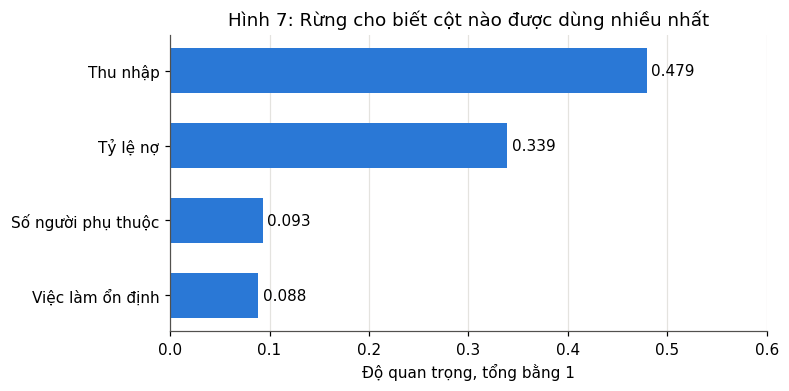

In [13]:
# Hình 7: độ quan trọng của bốn cột theo rừng 200 cây
ten_viet = {"thu_nhap": "Thu nhập", "ty_le_no": "Tỷ lệ nợ",
            "so_nguoi_phu_thuoc": "Số người phụ thuộc", "co_viec_on_dinh": "Việc làm ổn định"}
qt_sx = qt.sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
cot = ax.barh([ten_viet[c] for c in qt_sx.index], qt_sx.values, color=MAU_1, height=0.6)
ax.bar_label(cot, fmt="%.3f", padding=3); ax.set_xlim(0, 0.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("Độ quan trọng, tổng bằng 1")
ax.set_title("Hình 7: Rừng cho biết cột nào được dùng nhiều nhất"); plt.show()

**Nhận xét.** Với bốn cột thật, thu nhập được 0.479 và tỷ lệ nợ được 0.339, chiếm hơn bốn phần năm tổng số, khớp tài liệu (Hình 7). Số người phụ thuộc và việc làm ổn định chỉ được khoảng 0.09 mỗi cột.

Thêm cột `so_ngau_nhien` (chỉ là số rút ngẫu nhiên) thì nó được **0.150**, xếp thứ ba, trên cả hai cột thật. Phần này khớp tài liệu tới ±0.001 (tôi được 0.269 và 0.078 cho tỷ lệ nợ và việc làm, tài liệu ghi 0.270 và 0.077, cũng do khác phiên bản scikit-learn).

Hai giới hạn của `feature_importances_`:
1. **Cột có nhiều giá trị khác nhau được lợi.** Cột ngẫu nhiên có 450 giá trị khác nhau, nên ở nút sâu, nơi chỉ còn vài khách, cây luôn tìm được một ngưỡng tách được vài khách, và mỗi lần như vậy cột này được cộng điểm. Cột việc làm chỉ có đúng một cách chia (0 hoặc 1).
2. Độ quan trọng đo trên **tập học**, cho biết mô hình *dùng* cột nào nhiều, không chứng minh cột đó *có ích* trên dữ liệu mới, càng không chứng minh nó *gây ra* việc trả nợ đúng hạn.

Bài tập 5 kiểm lại bằng `permutation_importance`.

## 7. Cây cho bài toán hồi quy (`code/f7_cay_hoi_quy.py`)

In [14]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  Cay sau 3   : {mae_cay:.4f}")
print(f"  Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich     cay   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"    {dt:6.0f} m2   {a:6.2f}    {b:6.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
  Cay sau 3   : 0.5039
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich     cay   duong thang
        60 m2     4.92      5.12
       100 m2     8.32      8.24
       150 m2     9.40     12.13
       250 m2     9.40     19.91


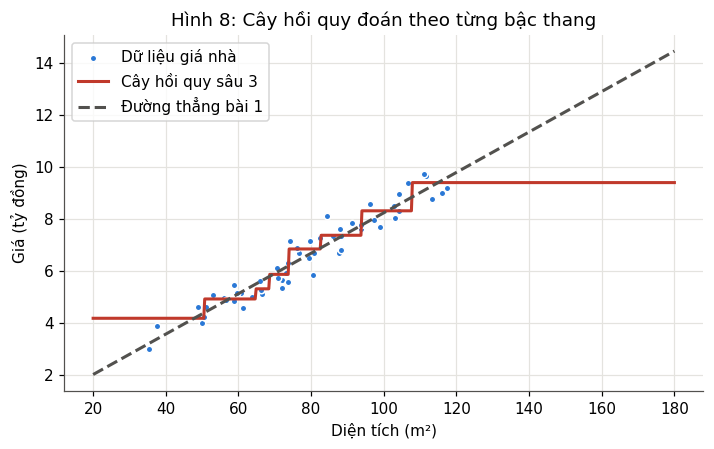

In [15]:
# Hình 8: đường dự đoán bậc thang của cây hồi quy sâu 3 và đường thẳng bài 1
xs = pd.DataFrame({"dien_tich": np.linspace(20, 180, 600)})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(X["dien_tich"], y, s=18, color=MAU_1, edgecolor="white", label="Dữ liệu giá nhà")
ax.plot(xs["dien_tich"], cay.predict(xs), color="#c0392b", label="Cây hồi quy sâu 3")
ax.plot(xs["dien_tich"], duong.predict(xs), "--", color=MAU_CHU, label="Đường thẳng bài 1")
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá (tỷ đồng)")
ax.set_title("Hình 8: Cây hồi quy đoán theo từng bậc thang"); ax.legend(loc="upper left"); plt.show()

**Nhận xét.** Khớp tài liệu. Cây sâu 3 có 8 lá, mỗi lá là một mức giá (trung bình giá của các căn trong lá), nên đường dự đoán là bậc thang 8 bậc (Hình 8). Ví dụ `value: [4.2]` nghĩa là mọi căn ≤ 50.5 m² đều được đoán 4.2 tỷ. Cây chọn ngưỡng để giảm **phương sai** của giá trong mỗi nhánh, thay cho Gini.

Đường thẳng thắng: MAE 0.2578 so với 0.5039 của cây. Giá tăng gần như thẳng theo diện tích, nên một đường thẳng mô tả đúng hơn một bậc thang. Cây sâu 3 còn kém cả KNN k = 5 của bài 4 (0.4030), vì nó chỉ có 8 mức giá.

**Cây không ngoại suy được.** Căn 150 m² và căn 250 m² đều được đoán 9.40 tỷ, vì cả hai lớn hơn 107.7 m² và rơi vào cùng lá cuối. Lá đó chỉ biết giá trung bình của những căn rộng nhất tập học. Giống KNN, cây chỉ nói lại những gì đã thấy.

---
# Bài tập

Mã của từng bài nằm trong `baitap05/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tự vẽ cây
Vẽ lại cây năm lá bằng `plot_tree`, lưu `cay_nam_la.png`; sau đó vẽ cây `max_depth=2`. Hai lá bên trái có cùng kết luận không? Nếu có, vì sao cây vẫn chia?

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
ten_cot = list(X.columns)
ten_lop = ["tre han", "dung han"]       # lớp 0 trước, lớp 1 sau


def ve_cay(cay, ten_tep, tieu_de, kich_thuoc):
    fig, ax = plt.subplots(figsize=kich_thuoc)
    plot_tree(cay, feature_names=ten_cot, class_names=ten_lop,
              filled=True, rounded=True, fontsize=10, ax=ax)
    ax.set_title(tieu_de)
    fig.savefig(ten_tep, dpi=150, bbox_inches="tight")
    plt.close(fig)                      # chỉ lưu tệp, không mở cửa sổ
    print(f"Da luu {ten_tep}")


nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, y_tr)
ve_cay(nam_la, "cay_nam_la.png", "Cay nam la (max_leaf_nodes=5)", (14, 7))

sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
ve_cay(sau_2, "cay_sau_2.png", "Cay sau 2 (max_depth=2)", (11, 5))
print()

print("Cay sau 2 dang chu:")
print(export_text(sau_2, feature_names=ten_cot, show_weights=True, decimals=3))

# Xem kỹ nút bên trái của gốc và hai lá con của nó
t = sau_2.tree_
trai = t.children_left[0]
la_1, la_2 = t.children_left[trai], t.children_right[trai]


def mo_ta(nut):
    # value lưu tỷ lệ (scikit-learn >= 1.4) hoặc số đếm (bản cũ); quy về số khách
    dem = t.value[nut][0] / t.value[nut][0].sum() * t.n_node_samples[nut]
    lop = ten_lop[int(dem.argmax())]
    return (f"{t.n_node_samples[nut]:3d} khach, tre {dem[0]:5.0f}, dung {dem[1]:5.0f}, "
            f"gini {t.impurity[nut]:.3f}, P(dung han) {dem[1] / dem.sum():.2f} -> {lop}")


print("Nhanh trai cua goc (thu_nhap <= 15.05)")
print(f"  nut cha : {mo_ta(trai)}")
print(f"  la trai : {mo_ta(la_1)}")
print(f"  la phai : {mo_ta(la_2)}")
n = t.n_node_samples
g_sau = (n[la_1] * t.impurity[la_1] + n[la_2] * t.impurity[la_2]) / n[trai]
print(f"  Gini truoc chia {t.impurity[trai]:.4f}, sau chia {g_sau:.4f}, "
      f"giam {t.impurity[trai] - g_sau:.4f}")

Da luu cay_nam_la.png
Da luu cay_sau_2.png

Cay sau 2 dang chu:
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Nhanh trai cua goc (thu_nhap <= 15.05)
  nut cha : 249 khach, tre   182, dung    67, gini 0.393, P(dung han) 0.27 -> tre han
  la trai : 121 khach, tre    68, dung    53, gini 0.492, P(dung han) 0.44 -> tre han
  la phai : 128 khach, tre   114, dung    14, gini 0.195, P(dung han) 0.11 -> tre han
  Gini truoc chia 0.3933, sau chia 0.3394, giam 0.0540


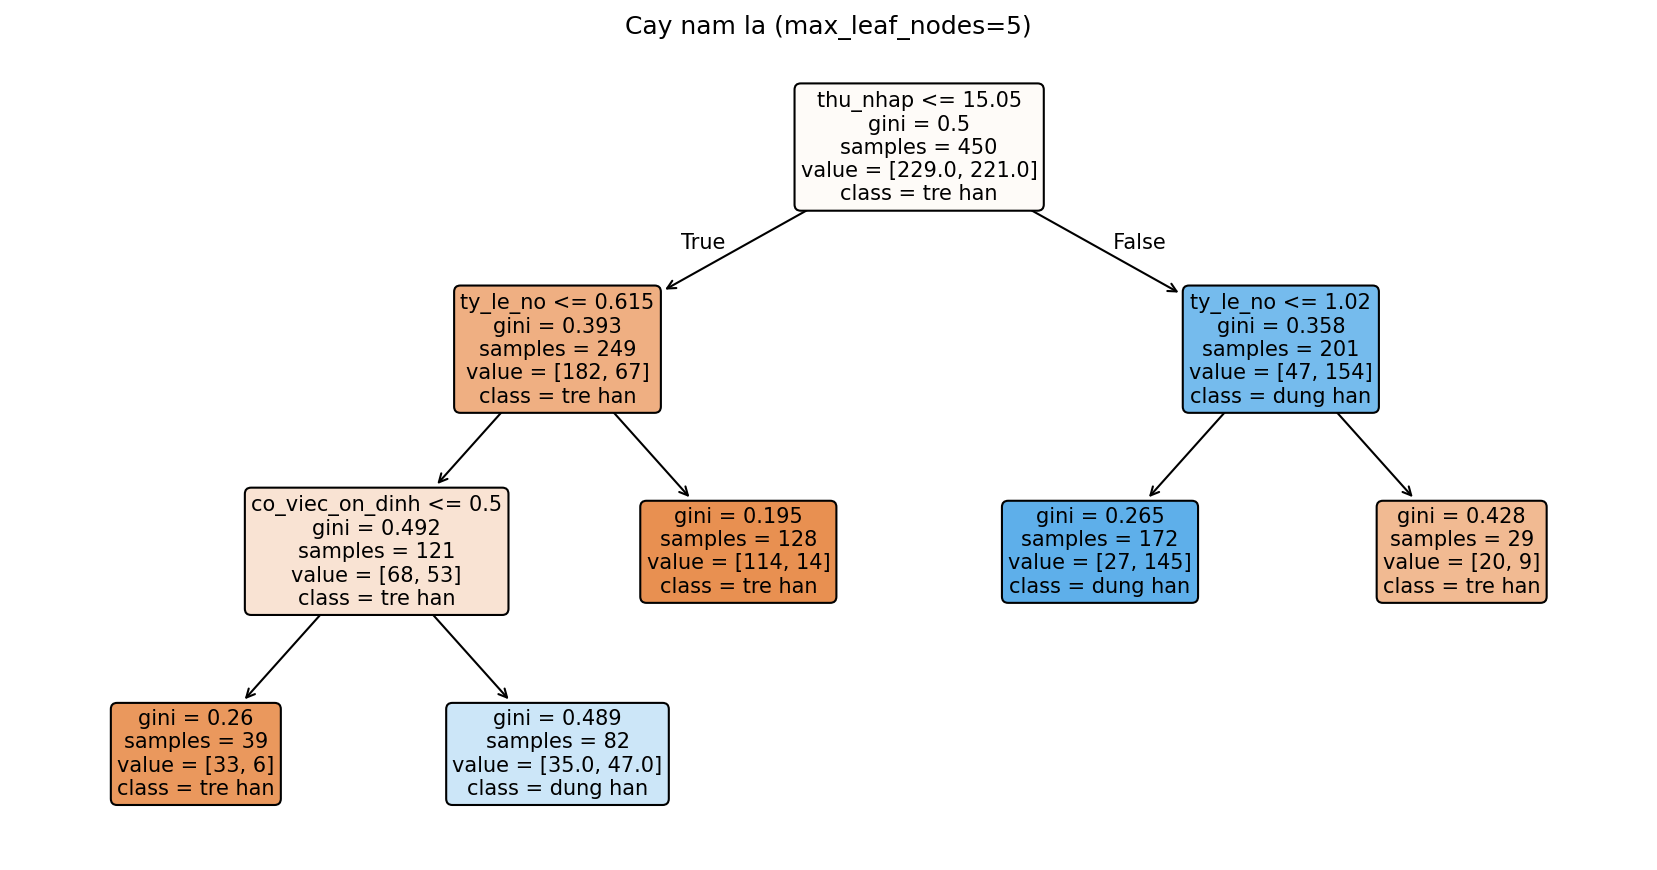

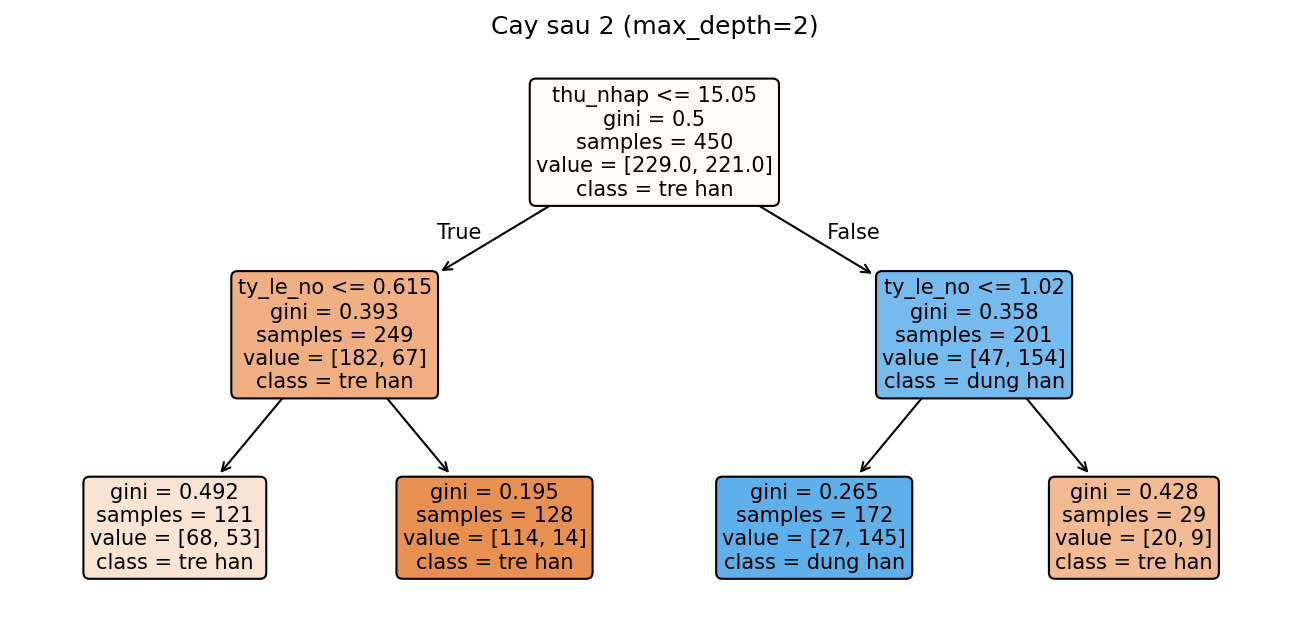

In [17]:
from IPython.display import Image, display
display(Image("cay_nam_la.png", width=900))
display(Image("cay_sau_2.png", width=700))

**Nhận xét.** `cay_nam_la.png` giống hệt Hình 2 của tài liệu. Cây sâu 2 chính là cây năm lá bỏ đi câu hỏi thứ ba về việc làm.

**Có, hai lá bên trái cùng kết luận "trễ hạn":** lá [68 trễ, 53 đúng] và lá [114 trễ, 14 đúng]. Cây vẫn chia vì nó không tối ưu nhãn đoán mà tối ưu **độ thuần** (Gini). Câu hỏi `ty_le_no <= 0.615` làm Gini của nhánh giảm từ 0.393 xuống 0.339 (giảm 0.054), vì nó tách nhóm 249 khách thành hai nhóm khác hẳn nhau: nhóm nợ nhiều gần như chắc chắn trễ (P(đúng hạn) = 0.11, Gini 0.195) và nhóm nợ ít gần như năm ăn năm thua (0.44, Gini 0.492).

Phép chia đó có ích dù nhãn không đổi, vì ba lý do:
- `predict_proba` khác hẳn: 0.11 so với 0.44. Ngân hàng nào đặt ngưỡng duyệt khác 0.5 (ví dụ chỉ duyệt khi P(đúng hạn) > 0.4) sẽ ra quyết định khác ở hai lá này.
- Cây được dựng **tham lam** từng tầng. Ở tầng 2, cây chưa biết tầng sau, nhưng việc tách riêng nhóm lẫn lộn [68, 53] mở đường cho câu hỏi tiếp theo về việc làm. Ở cây năm lá, đúng nhóm này được chia tiếp thành [33, 6] trễ hạn và [35, 47] đúng hạn.
- Cây chỉ dừng khi chạm giới hạn (ở đây `max_depth=2`) hoặc khi không còn câu hỏi nào làm Gini giảm, chứ không dừng khi hai con có cùng nhãn.

## Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật
Viết `tim_cau_hoi(X, y)` thử mọi cột và mọi ngưỡng, trả về cột và ngưỡng làm Gini giảm nhiều nhất; chạy trên 450 khách của tập học.

In [18]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(y, di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


def tim_cau_hoi(X, y):
    """Thu moi cot va moi nguong, tra ve (cot, nguong, Gini giam, bang tot nhat moi cot).

    X : DataFrame cac cot so
    y : nhan 0 / 1
    """
    y = np.asarray(y)
    g_goc = gini(y)
    tot = (None, None, -1.0)
    tung_cot = {}
    for cot in X.columns:
        gia_tri = X[cot].to_numpy()
        muc = np.unique(gia_tri)                     # đã sắp xếp tăng dần
        tot_cot = (None, -1.0)
        for a, b in zip(muc[:-1], muc[1:]):
            nguong = (a + b) / 2
            giam = g_goc - gini_sau_chia(y, gia_tri <= nguong)
            if giam > tot_cot[1]:
                tot_cot = (nguong, giam)
        tung_cot[cot] = (len(muc) - 1, *tot_cot)
        if tot_cot[1] > tot[2]:
            tot = (cot, tot_cot[0], tot_cot[1])
    return (*tot, tung_cot)


df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cot, nguong, giam, tung_cot = tim_cau_hoi(X_tr, y_tr)

print(f"Tap hoc {len(X_tr)} khach, Gini nut goc {gini(y_tr.to_numpy()):.4f}")
print()
print("Cau hoi tot nhat cua tung cot")
print("  cot                  so nguong thu   nguong tot   Gini giam")
for c, (so_nguong, ng, gm) in tung_cot.items():
    print(f"  {c:20s} {so_nguong:13d}   {ng:10.3f}   {gm:9.4f}")
print()
print(f"Cau hoi goc tu tim: {cot} <= {nguong:.3f}, Gini giam {giam:.4f}")

# So với câu hỏi gốc của cây scikit-learn
cay = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
cot_tv = X.columns[cay.tree_.feature[0]]
print(f"Cau hoi goc scikit-learn: {cot_tv} <= {cay.tree_.threshold[0]:.3f}")
print("Trung khop:", cot == cot_tv and np.isclose(nguong, cay.tree_.threshold[0]))

Tap hoc 450 khach, Gini nut goc 0.4998

Cau hoi tot nhat cua tung cot
  cot                  so nguong thu   nguong tot   Gini giam
  thu_nhap                       207       15.050      0.1221
  ty_le_no                       111        0.605      0.0586
  co_viec_on_dinh                  1        0.500      0.0329
  so_nguoi_phu_thuoc               4        2.500      0.0235

Cau hoi goc tu tim: thu_nhap <= 15.050, Gini giam 0.1221
Cau hoi goc scikit-learn: thu_nhap <= 15.050
Trung khop: True


**Nhận xét.** Hàm tự viết tìm ra **`thu_nhap <= 15.050`**, làm Gini giảm 0.1221 (từ 0.4998 ở gốc). Kết quả trùng tuyệt đối với câu hỏi gốc của mọi cây scikit-learn trong bài.

Cách hàm làm việc, cũng là cách cây chọn câu hỏi:
1. Với mỗi cột, lấy các giá trị khác nhau đã sắp xếp (`np.unique`) và chỉ thử ngưỡng **ở giữa hai giá trị liền nhau**. Mọi ngưỡng khác đều chia khách y như một trong các ngưỡng đó. Vì vậy thu nhập có 208 giá trị khác nhau nên phải thử 207 ngưỡng, còn `co_viec_on_dinh` chỉ có 1 ngưỡng (0.5).
2. Với mỗi ngưỡng, chia khách thành hai nhánh, tính Gini trung bình có trọng số, và lấy mức giảm so với Gini gốc.
3. Giữ câu hỏi có mức giảm lớn nhất trên mọi cột.

Bảng theo cột cho thấy thu nhập vượt trội: 0.1221, gấp đôi tỷ lệ nợ (0.0586), gấp gần 4 lần việc làm (0.0329) và gấp 5 lần số người phụ thuộc (0.0235). Thứ tự này khớp với độ quan trọng ở mục 6 (thu nhập rồi tỷ lệ nợ đứng đầu). Ngưỡng 15.05 là trung điểm của hai mức thu nhập liền nhau 15.0 và 15.1 trong tập học. scikit-learn cũng đặt ngưỡng ở trung điểm, nên hai bên khớp tới ba chữ số thập phân. Hàm này chỉ làm một bước; cây đầy đủ gọi lại đúng hàm này cho từng nhánh con với những khách rơi vào nhánh đó.

## Bài tập 3: Gini hay entropy
Chạy lại `f3_do_sau.py` với `criterion="entropy"`, ghi độ sâu tốt nhất và accuracy tập kiểm tra, so với Gini.

In [19]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def chay(tieu_chi):
    """Chon do sau bang kiem dinh cheo roi cham tap kiem tra mot lan."""
    tu_do = DecisionTreeClassifier(criterion=tieu_chi, random_state=0).fit(X_tr, y_tr)
    diem, hoc = {}, {}
    for d in range(1, 16):
        mh = DecisionTreeClassifier(criterion=tieu_chi, max_depth=d, random_state=0)
        diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
        hoc[d] = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    d_tot = max(diem, key=diem.get)
    tot = DecisionTreeClassifier(criterion=tieu_chi, max_depth=d_tot,
                                 random_state=0).fit(X_tr, y_tr)
    return {
        "tu_do": tu_do, "diem": diem, "hoc": hoc, "d_tot": d_tot, "tot": tot,
        "acc": accuracy_score(y_te, tot.predict(X_te)),
        "acc_tu_do": accuracy_score(y_te, tu_do.predict(X_te)),
        "du_doan": tot.predict(X_te),
    }


g = chay("gini")
e = chay("entropy")

print("Cay moc tu do, criterion = 'entropy'")
print(f"  do sau {e['tu_do'].get_depth()}, so la {e['tu_do'].get_n_leaves()}")
print(f"  tap hoc 1.0000, tap kiem tra {e['acc_tu_do']:.4f}")
print()

print("Do sau   tap hoc (entropy)   KDC entropy   KDC gini")
for d in range(1, 16):
    print(f"  {d:2d}     {e['hoc'][d]:.4f}              {e['diem'][d]:.4f}        "
          f"{g['diem'][d]:.4f}")
print()

print("Tong ket      do sau tot   so la   diem KDC   tap kiem tra")
for ten, r in [("gini", g), ("entropy", e)]:
    print(f"  {ten:9s}   {r['d_tot']:10d}   {r['tot'].get_n_leaves():5d}   "
          f"{r['diem'][r['d_tot']]:.4f}     {r['acc']:.4f}")
print()

# Hai cây tốt nhất có hỏi cùng câu hỏi gốc và đoán giống nhau không
for ten, r in [("gini", g), ("entropy", e)]:
    t = r["tot"].tree_
    print(f"Cau hoi goc ({ten:7s}): {X.columns[t.feature[0]]} <= {t.threshold[0]:.3f}")
print(f"So khach kiem tra bi doan khac nhau: {(g['du_doan'] != e['du_doan']).sum()} / {len(y_te)}")

Cay moc tu do, criterion = 'entropy'
  do sau 13, so la 88
  tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc (entropy)   KDC entropy   KDC gini
   1     0.7467              0.7244        0.7244
   2     0.7711              0.7133        0.7378
   3     0.7733              0.7489        0.7511
   4     0.8511              0.8111        0.8089
   5     0.8956              0.8222        0.8333
   6     0.9111              0.8222        0.8156
   7     0.9378              0.8089        0.8067
   8     0.9533              0.7933        0.7733
   9     0.9778              0.7844        0.7800
  10     0.9867              0.7978        0.7822
  11     0.9933              0.7911        0.7756
  12     0.9978              0.7822        0.7778
  13     1.0000              0.7822        0.7733
  14     1.0000              0.7822        0.7733
  15     1.0000              0.7867        0.7733

Tong ket      do sau tot   so la   diem KDC   tap kiem tra
  gini                 5      27   0.833

**Nhận xét.** Với entropy, kiểm định chéo vẫn chọn **độ sâu 5** (điểm 0.8222, cây 23 lá) và accuracy tập kiểm tra là **0.8467**, so với 0.8533 của Gini (độ sâu 5, 27 lá). Chênh 0.0067, tức 1 khách trên 150. Cây tự do với entropy cũng sâu 13 và đạt đúng 0.7667 trên tập kiểm tra như Gini (88 lá thay vì 92).

Hai cây tốt nhất hỏi cùng câu hỏi gốc `thu_nhap <= 15.05` và chỉ đoán khác nhau 7/150 khách. Hai đường kiểm định chéo đi gần như song song, cùng lên đỉnh ở độ sâu 5 hoặc 6 rồi cùng đi xuống.

**Một câu:** đổi thước đo từ Gini sang entropy gần như không làm kết quả khác đi; hai hàm đều bằng 0 khi nút thuần, đạt cực đại khi hai lớp chia đôi và có hình dạng rất giống nhau, nên chúng thường chọn cùng những câu hỏi lớn, chỉ khác ở vài nút sâu ít khách. Gini là mặc định vì tính nhanh hơn (không cần tính loga).

## Bài tập 4: Cắt tỉa bằng số khách tối thiểu ở lá
Cây không giới hạn độ sâu, đổi `min_samples_leaf` = 1, 2, 5, 10, 20, 40; chọn bằng kiểm định chéo 5 phần, chấm tập kiểm tra một lần, so với cây sâu 5.

In [20]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("min_samples_leaf   do sau   so la   tap hoc   kiem dinh cheo")
diem = {}
for m in [1, 2, 5, 10, 20, 40]:
    mh = DecisionTreeClassifier(min_samples_leaf=m, random_state=0)
    diem[m] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    mh.fit(X_tr, y_tr)
    hoc = accuracy_score(y_tr, mh.predict(X_tr))
    print(f"  {m:6d}           {mh.get_depth():4d}    {mh.get_n_leaves():4d}    "
          f"{hoc:.4f}    {diem[m]:.4f}")
m_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(min_samples_leaf=m_tot, random_state=0).fit(X_tr, y_tr)
acc = accuracy_score(y_te, tot.predict(X_te))

# Cây sâu 5 của mục 4, chọn bằng đúng cách đó
sau5 = DecisionTreeClassifier(max_depth=5, random_state=0)
diem_sau5 = cross_val_score(sau5, X_tr, y_tr, cv=5).mean()
sau5.fit(X_tr, y_tr)
acc_sau5 = accuracy_score(y_te, sau5.predict(X_te))

print("Cach cat tia              do sau   so la   diem KDC   tap kiem tra")
print(f"  min_samples_leaf = {m_tot:2d}   {tot.get_depth():6d}   {tot.get_n_leaves():5d}"
      f"   {diem[m_tot]:.4f}     {acc:.4f}")
print(f"  max_depth = 5           {sau5.get_depth():6d}   {sau5.get_n_leaves():5d}"
      f"   {diem_sau5:.4f}     {acc_sau5:.4f}")
print()

# Lá nhỏ nhất của cây sâu 5 có bao nhiêu khách
la = sau5.apply(X_tr)
print(f"Cay sau 5: la nho nhat co {pd.Series(la).value_counts().min()} khach, "
      f"so la duoi {m_tot} khach: {(pd.Series(la).value_counts() < m_tot).sum()}")

min_samples_leaf   do sau   so la   tap hoc   kiem dinh cheo
       1             13      92    1.0000    0.7733
       2             11      72    0.9467    0.7822
       5             10      46    0.8956    0.8067
      10              8      30    0.8600    0.8089
      20              7      17    0.8422    0.8089
      40              4       8    0.7822    0.7133

Cach cat tia              do sau   so la   diem KDC   tap kiem tra
  min_samples_leaf = 10        8      30   0.8089     0.8467
  max_depth = 5                5      27   0.8333     0.8533

Cay sau 5: la nho nhat co 1 khach, so la duoi 10 khach: 13


**Nhận xét.** `min_samples_leaf = 1` chính là cây tự do (sâu 13, 92 lá, kiểm định chéo 0.7733). Tăng số khách tối thiểu thì cây nông dần và ít lá dần, điểm kiểm định chéo tăng tới **0.8089 ở 10 và 20** rồi tụt mạnh còn 0.7133 ở 40 (8 lá, cây quá thô). Hai giá trị 10 và 20 hoà nhau chính xác, nên `max` lấy giá trị gặp trước là **10**. Chấm một lần trên tập kiểm tra được **0.8467** (cây sâu 8, 30 lá).

**Trên bộ dữ liệu này, cắt tỉa bằng `max_depth = 5` tốt hơn**: kiểm định chéo 0.8333 so với 0.8089, tập kiểm tra 0.8533 so với 0.8467. Hai cây có số lá tương đương (27 và 30) nhưng hình dạng khác nhau:
- `max_depth` cắt **đều theo chiều sâu**. Mọi đường đi tối đa 5 câu hỏi, nhưng lá có thể rất nhỏ: cây sâu 5 có lá chỉ 1 khách và 13 lá dưới 10 khách.
- `min_samples_leaf` cắt **theo cỡ nhóm**. Lá nào cũng đủ 10 khách, nhưng nhánh đông khách được mọc sâu tới 8 tầng.

Ở đây ranh giới hai lớp chủ yếu nằm trên thu nhập và tỷ lệ nợ, nên vài câu hỏi đầu đã làm phần lớn công việc. Giới hạn số tầng bắt cây dừng đúng lúc, còn giới hạn cỡ lá vẫn cho cây đào sâu ở vùng đông khách và học thêm nhiễu. Khác biệt chỉ 1 khách trên 150, và kiểm định chéo cũng xếp hạng đúng như tập kiểm tra. Lưu ý thêm: nếu chọn 20 thay vì 10 (cùng điểm kiểm định chéo) thì tập kiểm tra chỉ còn 0.8000, một ví dụ cho thấy điểm kiểm định chéo trên 450 khách vẫn còn nhiễu.

## Bài tập 5: Độ quan trọng bằng cách xáo trộn
Thêm cột ngẫu nhiên vào tập kiểm tra, dùng `permutation_importance(n_repeats=20, random_state=0)` cho rừng có cột `so_ngau_nhien`, so thứ hạng với `feature_importances_`.

In [21]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Lấy lại rừng có cột so_ngau_nhien của f6_do_quan_trong.py
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

# Thêm một cột ngẫu nhiên tương tự vào tập kiểm tra (rút tiếp từ cùng bộ sinh số)
X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))
print(f"Accuracy tap kiem tra cua rung co cot ngau nhien: "
      f"{accuracy_score(y_te, rung_nn.predict(X_te_nn)):.4f}")
print()

qt_cu = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
kq = permutation_importance(rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0)
qt_moi = pd.Series(kq.importances_mean, index=X_te_nn.columns)
lech = pd.Series(kq.importances_std, index=X_te_nn.columns)

hang_cu = qt_cu.rank(ascending=False).astype(int)
hang_moi = qt_moi.rank(ascending=False, method="min").astype(int)

print("Do quan trong theo hai cach do")
print("  cot                  feature_importances_ (hang)   xao tron: giam accuracy (hang)")
for c in qt_moi.sort_values(ascending=False).index:
    print(f"  {c:20s} {qt_cu[c]:.3f} ({hang_cu[c]})                    "
          f"{qt_moi[c]:+.4f} +- {lech[c]:.4f} ({hang_moi[c]})")
print()

# Mỗi lần xáo trộn, accuracy thay đổi bao nhiêu khách (mỗi khách là 1/n_kt)
n_kt = len(X_te_nn)
tung_lan = pd.Series(kq.importances[list(X_te_nn.columns).index("so_ngau_nhien")])
print("Cot so_ngau_nhien, 20 lan xao tron:")
print(f"  giam accuracy nho nhat {tung_lan.min():+.4f}, lon nhat {tung_lan.max():+.4f}")
print(f"  tuong ung {tung_lan.min() * n_kt:+.0f} toi {tung_lan.max() * n_kt:+.0f} khach "
      f"doan dung it di, tren {n_kt} khach kiem tra")

Accuracy tap kiem tra cua rung co cot ngau nhien: 0.9067



Do quan trong theo hai cach do
  cot                  feature_importances_ (hang)   xao tron: giam accuracy (hang)
  thu_nhap             0.427 (1)                    +0.3063 +- 0.0226 (1)
  ty_le_no             0.269 (2)                    +0.2010 +- 0.0362 (2)
  co_viec_on_dinh      0.078 (4)                    +0.1117 +- 0.0155 (3)
  so_nguoi_phu_thuoc   0.076 (5)                    +0.0497 +- 0.0199 (4)
  so_ngau_nhien        0.150 (3)                    +0.0003 +- 0.0111 (5)

Cot so_ngau_nhien, 20 lan xao tron:
  giam accuracy nho nhat -0.0133, lon nhat +0.0267
  tuong ung -2 toi +4 khach doan dung it di, tren 150 khach kiem tra


**Nhận xét.** Theo `permutation_importance`, cột `so_ngau_nhien` **xếp cuối cùng, thứ 5/5**. Xáo trộn nó làm accuracy giảm trung bình chỉ +0.0003 ± 0.0111, tức gần như bằng 0. Từng lần xáo trộn dao động từ −0.0133 tới +0.0267, tương ứng từ 2 khách đoán đúng *nhiều hơn* tới 4 khách đoán đúng ít hơn trên 150 khách: đó chỉ là nhiễu. Theo `feature_importances_`, cũng cột này lại xếp **thứ 3** với 0.150, trên cả việc làm ổn định và số người phụ thuộc.

Thứ hạng bốn cột thật theo xáo trộn: thu nhập (0.306), tỷ lệ nợ (0.201), việc làm ổn định (0.112), số người phụ thuộc (0.050). Đáng chú ý là **việc làm ổn định vượt lên thứ 3**, trong khi `feature_importances_` xếp nó gần cuối với 0.078.

**Vì sao hai cách đo khác nhau:**
- `feature_importances_` cộng mức giảm Gini mỗi lần một cột được dùng để chia, **trên tập học**. Cột ngẫu nhiên có 450 giá trị khác nhau, nên ở các nút sâu (rừng mọc tự do, lá chỉ vài khách) nó luôn tìm được ngưỡng tách được vài khách, và lần nào cũng được cộng điểm. Đó là điểm cho việc *học thuộc nhiễu*. Cột nhị phân như việc làm chỉ có một cách chia, nên bị thiệt dù rất có ích.
- `permutation_importance` hỏi một câu khác: *trên dữ liệu mô hình chưa thấy, nếu cột này mất hết thông tin thì mô hình kém đi bao nhiêu?* Xáo trộn cột ngẫu nhiên không làm hỏng gì, vì những ngưỡng học thuộc trên tập học vốn không đúng với khách mới. Xáo trộn việc làm thì sai thêm khoảng 11% khách, vì đây là thông tin thật mà rừng dựa vào.

Kết luận: `feature_importances_` cho biết mô hình **dùng** cột nào nhiều, còn `permutation_importance` trên tập kiểm tra cho biết cột nào **có ích** khi dự đoán. Khi phải nói cột nào quan trọng, nên dùng cách thứ hai. Dù vậy, cả hai đều không chứng minh quan hệ nhân quả.

## Bài tập 6: Rừng cho bài toán hồi quy
`RandomForestRegressor(n_estimators=200, random_state=0)` trên giá nhà, cùng cách chia mục 7; so MAE với cây sâu 3 và đường thẳng; dự đoán căn 250 m².

In [22]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

rung = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_tr, y_tr)
cay = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print("MAE tren tap kiem tra (ty dong)")
for ten, mh in [("Rung 200 cay", rung), ("Cay sau 3   ", cay), ("Duong thang ", duong)]:
    print(f"  {ten}: {mean_absolute_error(y_te, mh.predict(X_te)):.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich    rung     cay   duong thang")
for dt, a, b, c in zip(can_moi["dien_tich"], rung.predict(can_moi),
                       cay.predict(can_moi), duong.predict(can_moi)):
    print(f"    {dt:6.0f} m2  {a:6.2f}  {b:6.2f}    {c:6.2f}")
print()

# Mỗi cây trả về giá trung bình của lá mà căn 250 m2 rơi vào
can_250 = pd.DataFrame({"dien_tich": [250.0]})
tung_cay = np.array([c.predict(can_250.to_numpy())[0] for c in rung.estimators_])
rong_nhat = X_tr["dien_tich"].nlargest(5)
print("Can 250 m2")
print(f"  du doan cua rung (trung binh 200 cay): {rung.predict(can_250)[0]:.2f}")
print(f"  du doan cua tung cay: nho nhat {tung_cay.min():.2f}, lon nhat {tung_cay.max():.2f}")
print(f"  gia cao nhat trong tap hoc: {y_tr.max():.2f}")
print("  5 can rong nhat tap hoc:", ", ".join(
    f"{d:.1f} m2 = {y_tr[i]:.2f}" for i, d in rong_nhat.items()))
print(f"  rung doan can 150 m2 va 250 m2 giong nhau: "
      f"{np.isclose(rung.predict(can_moi)[2], rung.predict(can_moi)[3])}")

MAE tren tap kiem tra (ty dong)
  Rung 200 cay: 0.4559
  Cay sau 3   : 0.5039
  Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
  dien tich    rung     cay   duong thang
        60 m2    5.09    4.92      5.12
       100 m2    7.89    8.32      8.24
       150 m2    9.20    9.40     12.13
       250 m2    9.20    9.40     19.91

Can 250 m2
  du doan cua rung (trung binh 200 cay): 9.20
  du doan cua tung cay: nho nhat 8.52, lon nhat 9.74
  gia cao nhat trong tap hoc: 9.74
  5 can rong nhat tap hoc: 117.5 m2 = 9.19, 115.9 m2 = 9.01, 111.7 m2 = 9.67, 111.2 m2 = 9.74, 104.2 m2 = 8.97
  rung doan can 150 m2 va 250 m2 giong nhau: True


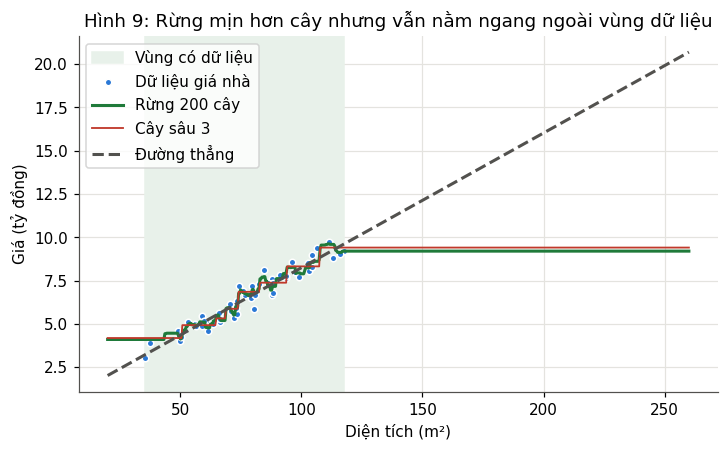

In [23]:
# Hình 9: rừng, cây sâu 3 và đường thẳng, kéo ra ngoài vùng dữ liệu
xs = pd.DataFrame({"dien_tich": np.linspace(20, 260, 600)})
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axvspan(X["dien_tich"].min(), X["dien_tich"].max(), color="#e8f1ea", label="Vùng có dữ liệu")
ax.scatter(X["dien_tich"], y, s=18, color=MAU_1, edgecolor="white", label="Dữ liệu giá nhà")
ax.plot(xs["dien_tich"], rung.predict(xs), color="#1f7a3a", label="Rừng 200 cây")
ax.plot(xs["dien_tich"], cay.predict(xs), color="#c0392b", lw=1.2, label="Cây sâu 3")
ax.plot(xs["dien_tich"], duong.predict(xs), "--", color=MAU_CHU, label="Đường thẳng")
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá (tỷ đồng)")
ax.set_title("Hình 9: Rừng mịn hơn cây nhưng vẫn nằm ngang ngoài vùng dữ liệu"); ax.legend(loc="upper left")
plt.show()

**Nhận xét.** MAE trên tập kiểm tra: rừng **0.4559**, cây sâu 3 0.5039, đường thẳng **0.2578**. Rừng tốt hơn một cây vì trung bình 200 cây cho một bậc thang mịn hơn nhiều (Hình 9). Nhưng rừng vẫn thua xa đường thẳng, vì quan hệ thật gần như thẳng, đúng giả định của hồi quy tuyến tính.

**Rừng không ngoại suy được.** Căn 250 m² được đoán **9.20 tỷ**, đúng bằng căn 150 m², trong khi đường thẳng đoán 19.91 tỷ. Giải thích theo cách lá đưa ra dự đoán: mỗi cây hồi quy trả về **giá trung bình của các căn trong lá** mà căn mới rơi vào. Căn 250 m² lớn hơn mọi ngưỡng của mọi cây, nên ở cây nào nó cũng rơi vào lá ngoài cùng bên phải. Rừng mặc định để cây mọc tự do, nên lá đó thường chỉ chứa căn rộng nhất mà cây được bốc (117.5 m² nếu bốc trúng, nếu không thì 115.9 m², 111.7 m², ...), và dự đoán của cây là giá của chính căn đó. Vì vậy:
- dự đoán của từng cây nằm trong khoảng 8.52 tới 9.74 tỷ, không cây nào vượt **9.74 tỷ, giá cao nhất tập học**;
- dự đoán của rừng là trung bình của 200 con số đó, nên cũng không thể vượt 9.74 tỷ.

Mọi căn từ khoảng 117 m² trở lên (sau căn rộng nhất 117.5 m²) đều nhận cùng một con số 9.20 tỷ, như đoạn nằm ngang trong Hình 9. Trung bình nhiều bậc thang chỉ làm bậc thang mịn hơn **bên trong** vùng có dữ liệu, chứ không kéo nó ra ngoài. Đây là giới hạn chung của KNN, cây và rừng: muốn ngoại suy phải dùng mô hình có giả định về hình dạng, như đường thẳng, và chấp nhận rủi ro giả định đó sai.